# Laboratorio 3 · Respuestas con fuentes: recuperar, citar y medir por componente

**Objetivo:** construir un índice sobre las políticas de una aerolínea ficticia, responder preguntas de pasajeros con citas y medir por separado si el recuperador encontró la evidencia y si el generador se sostuvo en ella; después, escribir preguntas propias y corregir una falla del generador con un solo cambio medido.

Trabajen en el equipo del proyecto y alternen quién ejecuta y quién revisa. El laboratorio se ejecuta en **Google Colab** con una cuenta personal de Google; no necesitas cuenta de GitHub.

El producto compartido se guarda en `labs/lab03-rag/`; cada integrante conserva su reflexión y su historial. Descarguen los archivos antes de cerrar Colab: los archivos de la sesión son temporales. La pregunta individual se responde en Canvas al cierre de la clase del 30/10; producto, reflexión e historial tienen plazo hasta el **martes 03/11/2026 a las 23:59, hora de Chile**.

El asistente que construimos informa lo que dicen las políticas; no decide devoluciones ni compensaciones.

## 1. Preparar el entorno

Guarda una copia del notebook en tu Drive y ejecuta la celda de instalación (tarda uno o dos minutos). Después agrega tu clave de Gemini como `GEMINI_API_KEY` o `GOOGLE_API_KEY` en **Secretos** (icono de llave de Colab) y permite que este notebook la lea. Nunca escribas su valor en una celda, captura o conversación.

En la celda de configuración, `MODE` puede ser `real` (consulta los modelos) o `simulated` (respuestas inventadas para practicar sin clave). Se abre en modo simulado; para la entrega cambia a `real` y vuelve a ejecutar.

**Modelo que responde.** En clase usa el servidor del curso (`curso:course-chat`), con `CURSO_API_KEY` y `CURSO_BASE_URL` en Secretos; el docente entrega la clave del día. Fuera de clase el servidor está apagado: elige `google:gemini-3.5-flash-lite`, gratis con tu clave de Gemini. `google:gemma-4-26b-a4b-it` queda como segunda opción: en la prueba del 28/10/2026 falló en 16 de 30 consultas. Indica en tu entrega cuál usaste.

**Embeddings.** El servidor del curso no los calcula: siempre se usa `gemini-embedding-2` con tu clave de Gemini. El paquete trae ya calculados los vectores del corpus y de las preguntas, con el mismo modelo, para no gastar la cuota en clase (`PRECOMPUTED = True`). Con `False` los calculas tú: unas 80 solicitudes, cerca de un minuto con el límite gratuito de 100 textos por minuto.

In [ ]:
import importlib.util
import subprocess
import sys
from pathlib import Path

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:  # fuera de Colab puede no existir el paquete google
    IN_COLAB = False

if IN_COLAB:
    # Rama de revisión docente; al publicar el laboratorio se cambia por la etiqueta "lab03".
    PACKAGE_REF = "lab03-corpus-20261028"
    # Para el ensayo docente: un ZIP del paquete subido a la sesión reemplaza la etiqueta.
    LOCAL_PACKAGE = Path("/content/curso-ia-lab03.zip")
    package_source = (f"curso-ia[lab03] @ file://{LOCAL_PACKAGE}" if LOCAL_PACKAGE.exists() else
                      f"curso-ia[lab03] @ git+https://github.com/udd-ia-generativa-2026/curso-ia@{PACKAGE_REF}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", package_source])
    print("Paquete instalado. Continúa con los secretos y la configuración.")
else:
    print("Fuera de Colab se usa el paquete del entorno de desarrollo.")

In [ ]:
import asyncio
import json
import os
from statistics import mean
from time import perf_counter

import pandas as pd
from pydantic import BaseModel, Field
from pydantic_ai import Agent

from curso_ia import create_model, load_config, save_experiment, status, timed_run
from curso_ia.rag import CourseEmbedding, load_corpus

# Cambia "simulated" por "real" para consultar los modelos con tus claves de Secretos.
MODE = "simulated"  # @param ["simulated", "real"]
os.environ["CURSO_MODE"] = MODE

# Modelo que responde, con la forma proveedor:modelo:
#   "curso:course-chat"             servidor del curso con Gemma 4 12B, solo durante las clases de los viernes;
#                                   requiere los secretos CURSO_API_KEY y CURSO_BASE_URL.
#   "google:gemini-3.5-flash-lite"  Gemini, gratis con tu clave de Gemini; para trabajar fuera de clase.
#   "google:gemma-4-26b-a4b-it"     Gemma 4, de pesos abiertos, gratis; segunda opción, a menudo lenta o saturada.
MODEL = "curso:course-chat"  # @param ["curso:course-chat", "google:gemini-3.5-flash-lite", "google:gemma-4-26b-a4b-it"]
os.environ["GENERATION_MODEL"] = MODEL

# Vectores del corpus incluidos en el paquete; con False se calculan con tu clave.
PRECOMPUTED = True  # @param {type: "boolean"}

# Servidor del curso sin Secretos: descomenta y pega la clave del día que entrega el docente.
# os.environ["CURSO_BASE_URL"] = "https://tofu.tail07b663.ts.net/v1"
# os.environ["CURSO_API_KEY"] = ""
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT = ROOT / "labs/lab03-rag"
config = load_config(ROOT)
model_ref = config.models["generation"]
embedding = CourseEmbedding(config.models["embedding"], config, precomputed=PRECOMPUTED)
print("Modo:", config.mode, "· Modelo:", model_ref, "· Embeddings:", config.models["embedding"],
      "· Vectores precalculados:", embedding.precomputed)
display(pd.DataFrame([row for row in status(config) if row["role"] != "comparison"]))

## 2. Conocer el corpus y las preguntas

El corpus son **siete políticas sintéticas** de Pacífico Sur, la aerolínea del laboratorio 2: equipaje, cambios de vuelo, devoluciones, retrasos y cancelaciones, asistencia especial, y check-in y embarque. La política de devoluciones tiene **dos versiones**: la vigente desde el 01/07/2026 y la anterior, derogada, que cambia plazos y cargos. Un sistema que no distingue la vigencia puede responder con una cita literal y aun así equivocarse.

Las **26 preguntas** están escritas como las haría un pasajero. Cada una trae una respuesta de referencia y las **frases literales esperadas**: los pedazos de las políticas que una buena respuesta necesita. Tres preguntas no tienen respuesta en el corpus (q08, q15 y q21) y sirven para medir si el sistema sabe abstenerse; dos (q25 y q26) exigen comprobar una condición que no se cumple. La recuperación se mide con las 26, pero solo **12** se envían al modelo en la sección 7, porque generar cuesta cuota y tiempo: la columna `in_generation` marca cuáles.

Al ejecutar la celda siguiente, las siete políticas quedan en la carpeta `corpus/` del panel **Archivos** (icono de carpeta, a la izquierda de Colab): ábrelas con doble clic para leerlas completas.

La referencia la propuso el asistente del curso: revisa algunas preguntas contra las políticas antes de confiar en las métricas, y anota en `REFERENCE_NOTES` lo que no compartas. Nunca la cambies para que coincida con una respuesta del sistema.

In [ ]:
documents, questions = load_corpus()

# Una copia de cada política en corpus/, para leerla desde el panel Archivos.
CORPUS_DIR = ROOT / "corpus"
CORPUS_DIR.mkdir(exist_ok=True)
for document in documents:
    (CORPUS_DIR / f"{document.metadata['doc_id']}.md").write_text(document.text, encoding="utf-8")

by_id = {question["id"]: question for question in questions}
REFERENCE_NOTES = ""  # Anota aquí desacuerdos con la referencia propuesta.

display(pd.DataFrame([document.metadata for document in documents]))
display(pd.DataFrame([{
    "id": q["id"], "question": q["question"], "answerable": q["answerable"],
    "evidence_quotes": len(q["expected_evidence"]), "in_generation": q["in_generation_subset"],
} for q in questions]))

In [ ]:
# Una pregunta con su evidencia esperada; cambia el id para mirar otras.
question = by_id["q17"]
print(question["question"], "\n\nRespuesta de referencia:", question["expected_answer"], "\n")
for evidence in question["expected_evidence"]:
    print(f"- {evidence['doc_id']}: «{evidence['quote']}»")

## 3. De documentos a fragmentos, vectores e índice

Un **fragmento** (*chunk*) es un pedazo de documento que se recupera por separado. `SentenceSplitter` corta cada política en fragmentos de un tamaño máximo en tokens sin partir oraciones, con un **solapamiento** del 10% para que una idea en el borde quede completa en alguno de los dos fragmentos.

El solapamiento se hace con oraciones completas: el final de un fragmento se repite al inicio del siguiente si cabe en el 10%. En la figura, con fragmentos de 200 tokens, `pol-equipaje#02` y `pol-equipaje#03` comparten una oración. Si la última oración es más larga que el solapamiento, los fragmentos no comparten nada: en este corpus pasa en muchos cortes.

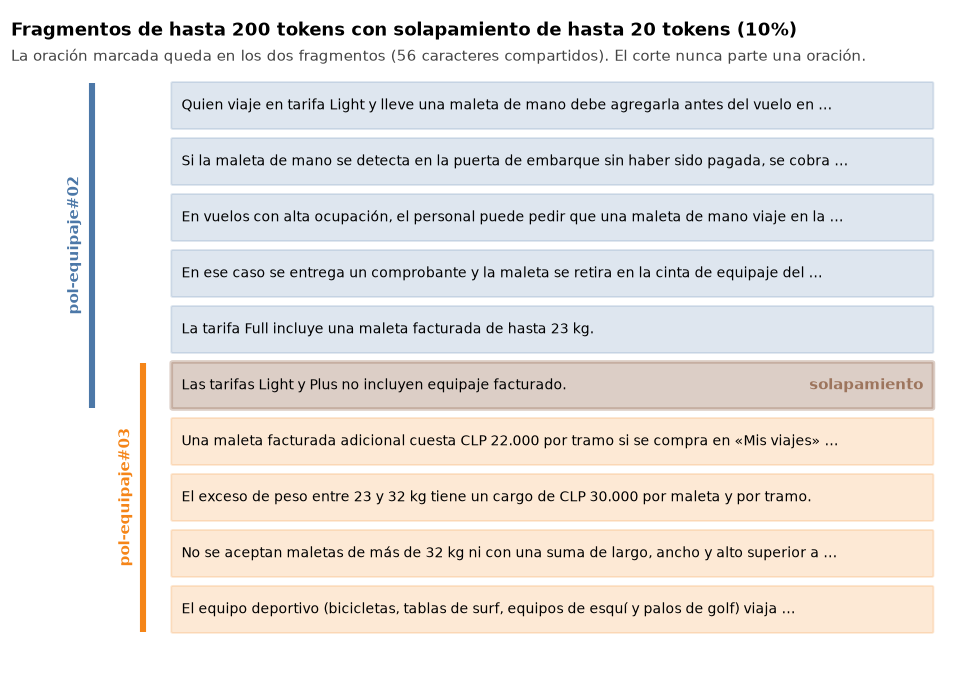

Un **embedding** es una lista de números (un vector) que ubica cerca los textos de significado parecido. Para buscar, se calcula el vector de la pregunta y se traen los fragmentos más cercanos. El **índice vectorial** guarda los fragmentos con sus vectores; usamos **Qdrant** en memoria, a través de LlamaIndex.

El índice guarda también **metadatos**: documento, título, vigencia y un identificador legible del fragmento (`pol-equipaje#03`), que usaremos para citar. Los metadatos no se mezclan con el texto que se convierte en vector: sirven para filtrar y para citar.

Construimos un índice por tamaño de fragmento: 200, 400 y 800 tokens. Mira cuántos fragmentos salen de cada uno.

In [ ]:
from llama_index.core import StorageContext, VectorStoreIndex
from llama_index.core.node_parser import SentenceSplitter
from llama_index.vector_stores.qdrant import QdrantVectorStore
from qdrant_client import QdrantClient

CHUNK_SIZES = [200, 400, 800]
qdrant = QdrantClient(location=":memory:")  # índice local, sin servidor; desaparece al cerrar la sesión


def build_index(chunk_size):
    """Cortar las políticas, nombrar cada fragmento y guardarlo en Qdrant con su vector."""
    splitter = SentenceSplitter(chunk_size=chunk_size, chunk_overlap=chunk_size // 10)
    nodes = splitter.get_nodes_from_documents(documents)
    counters = {}
    for node in nodes:
        doc_id = node.metadata["doc_id"]
        counters[doc_id] = counters.get(doc_id, 0) + 1
        node.metadata["chunk_id"] = f"{doc_id}#{counters[doc_id]:02d}"
        node.excluded_embed_metadata_keys.append("chunk_id")
        node.excluded_llm_metadata_keys.append("chunk_id")
    store = QdrantVectorStore(client=qdrant, collection_name=f"policies-{chunk_size}")
    index = VectorStoreIndex(nodes, storage_context=StorageContext.from_defaults(vector_store=store),
                             embed_model=embedding)
    return index, nodes


indexes, chunks = {}, {}
for size in CHUNK_SIZES:
    indexes[size], chunks[size] = build_index(size)
    print(f"Fragmentos de {size} tokens: {len(chunks[size])}")
print("Textos enviados al proveedor de embeddings hasta ahora:", embedding.requests)

In [ ]:
# Los tres fragmentos más parecidos a una pregunta, con fragmentos de 200 tokens; cambia el id o el tamaño.
# Una pregunta nueva calcula su vector con tu clave; las del conjunto ya lo traen.
demo = by_id["q02"]["question"]
DEMO_SIZE = 200
ranking = indexes[DEMO_SIZE].as_retriever(similarity_top_k=len(chunks[DEMO_SIZE])).retrieve(demo)
print(demo, "\n")
for rank, result in enumerate(ranking[:3], start=1):
    print(f"──── {rank}.º · {result.node.metadata['chunk_id']} · similitud {result.score:.3f}")
    print(result.node.get_content(), "\n")

# Similitud de la pregunta con todos los fragmentos: el recuperador se queda con los k primeros (aquí, 3).
similarity = pd.Series({result.node.metadata["chunk_id"]: result.score for result in ranking})
colors = ["tab:blue" if rank < 3 else "lightgray" for rank in range(len(similarity))]
axis = similarity.plot.barh(figsize=(7, 0.22 * len(similarity) + 1), color=colors, xlabel="similitud",
                            title=f"Similitud con cada fragmento de {DEMO_SIZE} tokens")
axis.invert_yaxis()


## 4. Medir el recuperador sin modelo de lenguaje

Antes de generar, medimos si la búsqueda trae la evidencia. Un fragmento recuperado es **relevante** si contiene alguna de las frases literales esperadas; así la referencia no depende del tamaño del fragmento y no hace falta un juez.

- **recall@k** (`recall_at_k`): qué parte de las frases esperadas llegó entre los *k* primeros fragmentos. 1 significa que llegó toda.
- **Tasa de aciertos** (*hit rate*, `hit_rate`): en qué parte de las preguntas llegó al menos una frase esperada.
- **MRR** (*mean reciprocal rank*, `mrr`): en qué posición aparece el primer fragmento relevante; vale 1 si es el primero, 0,5 si es el segundo, 0,33 si es el tercero y 0 si no aparece entre los *k*.
- **Derogada en el top-k** (`derogated_in_top`): en qué parte de las preguntas se coló un fragmento de la política derogada (`pol-devoluciones-2024`) entre los *k* recuperados. 0,29 significa que pasó en el 29% de las preguntas.

El **filtro de vigencia** usa los metadatos: Qdrant descarta la política derogada antes de comparar vectores. Las tres preguntas sin respuesta no entran en recall, aciertos ni MRR, pero sí en la columna de la derogada.

Barrido corto: tres tamaños por *k* de 3 y 5, con y sin filtro (12 configuraciones). Todo corre en tu sesión: cada pregunta calcula su vector una sola vez.

In [ ]:
from llama_index.core.vector_stores import MetadataFilter, MetadataFilters

CURRENT_ONLY = MetadataFilters(filters=[MetadataFilter(key="status", value="vigente")])


def retrieve(chunk_size, text, k, current_only):
    retriever = indexes[chunk_size].as_retriever(similarity_top_k=k, filters=CURRENT_ONLY if current_only else None)
    return retriever.retrieve(text)


def retrieval_scores(question, retrieved):
    """recall@k, acierto y rango recíproco de una pregunta, comparando frases literales."""
    texts = [result.node.get_content() for result in retrieved]
    quotes = [evidence["quote"] for evidence in question["expected_evidence"]]
    found = [any(quote in text for text in texts) for quote in quotes]
    ranks = [rank for rank, text in enumerate(texts, start=1) if any(quote in text for quote in quotes)]
    return {
        "recall": mean(found) if quotes else None,
        "hit": any(found) if quotes else None,
        "reciprocal_rank": (1 / ranks[0] if ranks else 0.0) if quotes else None,
        "derogated_in_top": any(result.node.metadata["status"] == "derogada" for result in retrieved),
    }


def summarize(rows):
    answerable = [row for row in rows if row["recall"] is not None]
    return {
        "recall_at_k": round(mean(row["recall"] for row in answerable), 2),
        "hit_rate": round(mean(row["hit"] for row in answerable), 2),
        "mrr": round(mean(row["reciprocal_rank"] for row in answerable), 2),
        "derogated_in_top": round(mean(row["derogated_in_top"] for row in rows), 2),
    }


sweep, per_question = [], []
for size in CHUNK_SIZES:
    for current_only in (False, True):
        for k in (3, 5):
            rows = []
            for question in questions:
                retrieved = retrieve(size, question["question"], k, current_only)
                rows.append({"id": question["id"], "chunk_size": size, "k": k, "current_only": current_only,
                             **retrieval_scores(question, retrieved),
                             "retrieved": [result.node.metadata["chunk_id"] for result in retrieved]})
            per_question += rows
            sweep.append({"chunk_size": size, "chunks": len(chunks[size]), "k": k, "current_only": current_only,
                          "rerank": False, **summarize(rows)})

metrics = pd.DataFrame(sweep)
display(metrics)
print("Textos enviados al proveedor de embeddings:", embedding.requests)

## 5. Elegir una configuración

En un corpus tan pequeño el recuperador casi no falla con *k* = 5. La decisión no es «el número más alto», sino un equilibrio entre la evidencia encontrada, el texto que se envía al modelo en cada consulta (*k* × tamaño del fragmento), la vigencia de la fuente y la precisión de la cita: con fragmentos de 800 tokens y *k* = 5 se envía la mitad del corpus.

Partimos de un sistema **sin filtro de vigencia**, como el que se arma cuando nadie piensa en las versiones de un documento. Así verán en la generación qué produce, y en la sección 9 podrán elegir el filtro como su corrección. Elige tamaño y *k*, y mira las fallas pregunta por pregunta. La tabla muestra solo las preguntas con algún problema:

- `recall` menor que 1: alguna frase esperada no llegó entre los *k* fragmentos.
- `derogated_in_top` en `True`: entre los *k* fragmentos de esa pregunta llegó uno de la política derogada; búscalo en `retrieved` (los que empiezan por `pol-devoluciones-2024`).

Cualquiera de las dos es una **falla de recuperación** candidata para el reporte. Las preguntas sin respuesta tienen `recall` vacío y solo aparecen por la derogada.

In [ ]:
CHUNK_SIZE = 400  # @param [200, 400, 800]
TOP_K = 5  # @param [3, 5]
CURRENT_ONLY_FILTER = False  # @param {type: "boolean"}

chosen = pd.DataFrame(per_question).query(
    "chunk_size == @CHUNK_SIZE and k == @TOP_K and current_only == @CURRENT_ONLY_FILTER")
print(f"Configuración elegida: fragmentos de {CHUNK_SIZE}, k = {TOP_K}, filtro de vigencia: {CURRENT_ONLY_FILTER}")
failures = chosen[(chosen["recall"] < 1) | chosen["derogated_in_top"]].merge(
    pd.DataFrame(questions)[["id", "question"]], on="id")
with pd.option_context("display.max_colwidth", None):
    display(failures[["id", "question", "recall", "derogated_in_top", "retrieved"]])

## 6. Escribir preguntas propias

Un conjunto de evaluación vale lo que valen sus preguntas. Escriban **tres preguntas** sobre las políticas de Pacífico Sur, como las haría un pasajero, y señalen las oraciones de las políticas que una buena respuesta necesita:

1. Una que se responda con una sola oración.
2. Una que necesite dos oraciones de secciones o documentos distintos.
3. Una **sin respuesta** en el corpus, pero sobre un tema parecido a algo que sí está (como q08, q15 y q21): su evidencia queda vacía.

Para encontrar la evidencia no hace falta copiar texto: `buscar("maleta")` muestra las oraciones que contienen esa palabra, cada una con un identificador como `pol-equipaje:12`, y en la pregunta se anotan esos identificadores. `buscar("", "pol-retrasos")` muestra una política completa, oración por oración.

Eviten copiar las palabras de la política en la pregunta: un pasajero dice «valija», no «equipaje facturado», y esa diferencia es la que pone a prueba al recuperador. Las preguntas válidas se miden con el recuperador y entran a la generación de las secciones siguientes. Cada pregunta nueva calcula su vector con tu clave (en modo simulado recibe un vector al azar).

Más adelante harán lo mismo con los documentos de su proyecto para el Hito 1.

In [ ]:
from curso_ia.rag import sentences

sentence_table = pd.DataFrame(sentences(documents)).set_index("id")


def buscar(texto, doc_id=None):
    """Oraciones que contienen el texto (sin distinguir mayúsculas), opcionalmente de una sola política."""
    found = sentence_table[sentence_table["sentence"].str.contains(texto, case=False, regex=False)]
    if doc_id:
        found = found[found["doc_id"] == doc_id]
    with pd.option_context("display.max_colwidth", None, "display.max_rows", 200):
        display(found[["sentence"]])


# Políticas: pol-equipaje, pol-cambios, pol-devoluciones-2026, pol-devoluciones-2024 (derogada),
# pol-retrasos, pol-asistencia, pol-embarque. Cambia la palabra y vuelve a ejecutar.
buscar("maleta")

In [ ]:
# La evidencia se escribe con los identificadores que muestra buscar(), por ejemplo "pol-equipaje:12".
MY_QUESTIONS = [
    {"id": "p01", "question": "", "expected_answer": "", "evidence_ids": [""]},
    {"id": "p02", "question": "", "expected_answer": "", "evidence_ids": ["", ""]},
    {"id": "p03", "question": "", "expected_answer": "Las políticas no tratan este tema.", "evidence_ids": []},
]


def problems(item):
    """Lo que impide usar una pregunta propia: pregunta vacía o identificadores que no existen."""
    found = [] if item["question"].strip() else ["falta la pregunta"]
    found += [f"no existe la oración {sentence_id!r}" for sentence_id in item["evidence_ids"]
              if sentence_id not in sentence_table.index]
    return found


own = []
for item in MY_QUESTIONS:
    if issues := problems(item):
        print(item["id"], "·", "; ".join(issues))
        continue
    evidence = [{"doc_id": sentence_table.loc[sentence_id, "doc_id"], "quote": sentence_table.loc[sentence_id, "sentence"]}
                for sentence_id in item["evidence_ids"]]
    own.append({"id": item["id"], "question": item["question"], "expected_answer": item["expected_answer"],
                "expected_evidence": evidence, "answerable": bool(evidence), "in_generation_subset": True})
by_id.update({question["id"]: question for question in own})
print(f"Preguntas propias válidas: {len(own)} de {len(MY_QUESTIONS)}")

own_retrieval = []
for question in own:
    retrieved = retrieve(CHUNK_SIZE, question["question"], TOP_K, CURRENT_ONLY_FILTER)
    own_retrieval.append({"id": question["id"], "question": question["question"],
                          **retrieval_scores(question, retrieved),
                          "retrieved": [result.node.metadata["chunk_id"] for result in retrieved]})
if own_retrieval:
    with pd.option_context("display.max_colwidth", None):
        display(pd.DataFrame(own_retrieval))

## 7. Responder con citas

Comparamos tres formas de responder la **misma pregunta**, con la misma instrucción y el mismo modelo; solo cambia el contexto:

1. `no_documents`: sin documentos. Sobre una aerolínea ficticia, el modelo solo puede abstenerse o inventar.
2. `full_corpus`: todos los fragmentos del corpus en la consulta, incluida la política derogada. Es posible porque el corpus es pequeño, pero envía todo cada vez.
3. `retrieval`: solo los *k* fragmentos recuperados con la configuración elegida.

La salida es tipada, como en el laboratorio 2: la respuesta, una lista de **citas** (identificador del fragmento y frase copiada literalmente de él) y una marca de **abstención** para cuando la evidencia no alcanza. Corremos el subconjunto de 12 preguntas, que incluye las tres sin respuesta y dos que exigen comprobar una condición antes de responder (q25 y q26), más sus preguntas propias: unas 45 consultas. Recuerden que partimos sin filtro de vigencia: en `retrieval` puede llegar la política derogada. En modo simulado las respuestas están preparadas y no se miden tiempos ni tokens.

In [ ]:
class Citation(BaseModel):
    chunk_id: str = Field(description="Identificador del fragmento citado, por ejemplo pol-equipaje#03")
    quote: str = Field(description="Frase copiada literalmente del fragmento que respalda la respuesta")


class Answer(BaseModel):
    answer: str = Field(description="Respuesta al pasajero, breve y en español")
    citations: list[Citation] = Field(description="Una cita por cada afirmación de la respuesta")
    abstained: bool = Field(description="true si los fragmentos no permiten responder")


INSTRUCTION = """
Eres el asistente de atención de Pacífico Sur. Responde la pregunta del pasajero usando solo los fragmentos entregados.
Cada afirmación debe tener una cita con el identificador del fragmento y una frase copiada literalmente de él.
Si los fragmentos no permiten responder, marca abstained=true y no inventes.
""".strip()
SETTINGS = {"temperature": 1.0, "max_tokens": 1500}
MODES = ["no_documents", "full_corpus", "retrieval"]
SIMULATED_ANSWER = {"answer": "Respuesta simulada; no proviene de ningún modelo.", "citations": [], "abstained": True}


def context_for(mode, question, current_only=None):
    """Fragmentos que recibe el modelo en cada modo; por defecto, con el filtro elegido en la sección 5."""
    if mode == "no_documents":
        return []
    if mode == "full_corpus":
        return chunks[CHUNK_SIZE]
    current_only = CURRENT_ONLY_FILTER if current_only is None else current_only
    return [result.node for result in retrieve(CHUNK_SIZE, question["question"], TOP_K, current_only)]


# Vigencia de cada fragmento, para saber si una cita viene de la política derogada.
chunk_status = {node.metadata["chunk_id"]: node.metadata["status"] for size in CHUNK_SIZES for node in chunks[size]}


def prompt_for(question, context):
    fragments = "\n\n".join(f"[{node.metadata['chunk_id']}] {node.metadata['title']}\n{node.get_content()}"
                             for node in context)
    return f"Fragmentos:\n{fragments or '(ninguno)'}\n\nPregunta: {question['question']}"


subset = [question for question in questions if question["in_generation_subset"]] + own
print(prompt_for(subset[0], context_for("retrieval", subset[0])))

In [ ]:
async def answer(question, mode, instruction=INSTRUCTION, validator=None, version="v1", current_only=None):
    """Una consulta: el agente recibe en `deps` los fragmentos que vio, por si un validador los necesita."""
    nodes = context_for(mode, question, current_only)
    context = {node.metadata["chunk_id"]: node.get_content() for node in nodes}
    model = create_model(model_ref, config, simulated_output=SIMULATED_ANSWER)
    agent = Agent(model, output_type=Answer, instructions=instruction, deps_type=dict,
                  model_settings=SETTINGS, retries=1)
    if validator:
        agent.output_validator(validator)
    row = await timed_run(agent, prompt_for(question, nodes), ref=model_ref, config=config, deps=context)
    return {"version": version, "context_mode": mode, "id": question["id"], "attempts": 1, "context": context, **row}


# Límites gratuitos (AI Studio): consultas y tokens por minuto. Con todo el corpus, Gemma admite pocas consultas
# por minuto, así que después de cada una se espera lo que pidan sus tokens.
LIMITS = {"google:gemma-4-26b-a4b-it": (30, 16_000), "google:gemini-3.5-flash-lite": (15, 250_000)}


def pause_after(row):
    if config.mode != "real" or model_ref not in LIMITS:
        return 0
    per_minute, tokens_per_minute = LIMITS[model_ref]
    return max(60 / per_minute, 60 * (row.get("input_tokens") or 0) / tokens_per_minute)


def service_failure(row):
    """Falló el servicio, no la consulta: se puede reintentar. Un 400 o un 401 volvería a fallar igual."""
    if row.get("error_type") in ("UnexpectedModelBehavior", "UsageLimitExceeded"):
        return False  # el modelo no cumplió el esquema o el validador: es un resultado, no una falla del servicio
    code = row.get("http_status")
    return row["status"] == "error" and (code is None or code == 429 or code >= 500)


async def run_batch(jobs, **options):
    """Ejecutar pares (pregunta, modo) con espera entre consultas y un reintento de las fallas del servicio."""
    rows = []
    for question, mode in jobs:
        row = await answer(question, mode, **options)
        rows.append(row)
        print(question["id"], mode, row["status"], row.get("error_type", ""), flush=True)
        await asyncio.sleep(pause_after(row))
    failed = [index for index, row in enumerate(rows) if service_failure(row)]
    if failed:
        print(f"Reintentando una vez {len(failed)} consultas fallidas en 20 s…")
        await asyncio.sleep(20)
    for index in failed:
        question, mode = by_id[rows[index]["id"]], rows[index]["context_mode"]
        rows[index] = {**await answer(question, mode, **options), "attempts": 2}
        print(question["id"], mode, rows[index]["status"], rows[index].get("error_type", ""))
    print("Consultas con error:", sum(row["status"] == "error" for row in rows), "de", len(rows))
    return rows


answers = await run_batch([(question, mode) for question in subset for mode in MODES])

## 8. Comprobar las citas y la abstención

Ahora medimos el **generador** sin juez:

- **Cita verificable**: el fragmento citado estaba en el contexto que recibió el modelo y contiene la frase citada, letra por letra. Una cita verificable no prueba que la fuente sea la correcta: una cita literal de la política derogada pasa esta prueba y la respuesta es falsa.
- **Abstención correcta**: se abstuvo en las preguntas sin respuesta y respondió en las demás.
- **Evidencia esperada citada**: alguna cita contiene una de las frases esperadas, o está contenida en ella.
- **Cita derogada**: alguna cita viene de un fragmento de la política derogada.

La corrección de la respuesta frente a la referencia la revisan ustedes: lean la tabla y elijan una **falla de generación**, la que corregirán en la sección 9. Miren en especial q17 y q24 (¿qué versión citó?) y q25 y q26 (¿comprobó la condición o respondió «sí» con una cita correcta?). Si la falla está en el recuperador (la evidencia no llegó), no se arregla en el generador.

In [ ]:
def citation_checks(row):
    if row["status"] != "ok":
        return {"citations": 0, "verifiable": 0, "cites_expected": False, "cites_derogated": False}
    citations = row["output"]["citations"]
    quotes = [evidence["quote"] for evidence in by_id[row["id"]]["expected_evidence"]]
    verifiable = [c["chunk_id"] in row["context"] and c["quote"] in row["context"][c["chunk_id"]] for c in citations]
    cites_expected = any(c["quote"] in quote or quote in c["quote"] for c in citations for quote in quotes)
    cites_derogated = any(chunk_status.get(c["chunk_id"]) == "derogada" for c in citations)
    return {"citations": len(citations), "verifiable": sum(verifiable), "cites_expected": cites_expected,
            "cites_derogated": cites_derogated}


def generation_table(rows):
    table = pd.DataFrame([{
        "id": row["id"], "version": row["version"], "context_mode": row["context_mode"], "status": row["status"],
        "answerable": by_id[row["id"]]["answerable"],
        "abstained": row["output"]["abstained"] if row["status"] == "ok" else None,
        **citation_checks(row),
        "requests": row.get("requests"), "input_tokens": row.get("input_tokens"), "latency_ms": row.get("latency_ms"),
        "answer": row["output"]["answer"] if row["status"] == "ok" else "",
        "expected_answer": by_id[row["id"]]["expected_answer"],
    } for row in rows])
    table["correct_abstention"] = table["abstained"] == ~table["answerable"]
    return table


def generation_summary(table, by):
    return table[table["status"] == "ok"].groupby(by).agg(
        answers=("id", "size"), correct_abstention=("correct_abstention", "sum"),
        citations=("citations", "sum"), verifiable=("verifiable", "sum"), cites_expected=("cites_expected", "sum"),
        cites_derogated=("cites_derogated", "sum"), median_input_tokens=("input_tokens", "median"), median_latency_ms=("latency_ms", "median"),
    )


generation = generation_table(answers)
display(generation_summary(generation, "context_mode").reindex(MODES))
with pd.option_context("display.max_colwidth", None):
    display(generation[["id", "context_mode", "abstained", "citations", "verifiable", "cites_derogated",
                        "answer", "expected_answer"]])

## 9. Corregir el generador con un solo cambio

Con la falla elegida, cambien **una sola cosa** y vuelvan a medir el modo `retrieval` con las mismas preguntas. Hay tres caminos, y cada uno sirve para un tipo de falla:

- **La instrucción** (`INSTRUCTION_V2`): una regla que falta. Por ejemplo, que antes de responder «sí» compruebe que se cumplen todas las condiciones de la política (q25 y q26), o qué hacer cuando dos fragmentos dicen cosas distintas.
- **Un validador de citas** (`VALIDATE_CITATIONS = True`): PydanticAI revisa cada respuesta antes de aceptarla. `citations_in_context` rechaza las citas que no aparecen letra por letra en su fragmento o que vienen de la política derogada, y le devuelve al modelo un mensaje para que corrija (`ModelRetry`). Es una regla del sistema, no una petición al modelo: si el modelo no corrige en el segundo intento, la consulta queda como falla. La columna `requests` muestra cuándo hubo que pedir la corrección.
- **El filtro de vigencia** (`CURRENT_ONLY_FILTER_V2 = True`): el cambio está en el recuperador, no en el generador; la derogada ni siquiera llega al modelo. Sirve para comparar: ¿qué conviene, impedir que llegue o rechazar la respuesta que la cita?

Si cambian dos cosas a la vez, no sabrán cuál produjo el resultado. Comparen antes y después pregunta por pregunta: ¿se corrigió la falla?, ¿se rompió algo que antes funcionaba?, ¿cuánto costó en consultas y tiempo? No todas las fallas tienen arreglo con un solo cambio: eso también es un resultado.

In [ ]:
from pydantic_ai import ModelRetry, RunContext

INSTRUCTION_V2 = INSTRUCTION  # Edítala si el cambio es la instrucción.
VALIDATE_CITATIONS = False  # Ponlo en True si el cambio es el validador de citas.
CURRENT_ONLY_FILTER_V2 = CURRENT_ONLY_FILTER  # Ponlo en True si el cambio es el filtro de vigencia.
CHANGE = ""  # Qué cambiaron y qué falla quieren corregir, en una frase.


def citations_in_context(ctx: RunContext[dict], output: Answer) -> Answer:
    """Aceptar la respuesta solo si cada cita aparece tal cual en un fragmento vigente que el modelo recibió."""
    not_literal = [c.chunk_id for c in output.citations if c.chunk_id not in ctx.deps or c.quote not in ctx.deps[c.chunk_id]]
    derogated = [c.chunk_id for c in output.citations if chunk_status.get(c.chunk_id) == "derogada"]
    problems_found = []
    if not_literal:
        problems_found.append(f"no aparecen literalmente en su fragmento: {', '.join(not_literal)}")
    if derogated:
        problems_found.append(f"vienen de una política derogada: {', '.join(derogated)}")
    if problems_found:
        raise ModelRetry("Estas citas " + "; ".join(problems_found) + ". Usa solo frases exactas de políticas vigentes, "
                         "o quita la afirmación.")
    return output


changes = (INSTRUCTION_V2 != INSTRUCTION) + VALIDATE_CITATIONS + (CURRENT_ONLY_FILTER_V2 != CURRENT_ONLY_FILTER)
answers_v2 = []
if changes == 0:
    print("No hay cambio: edita INSTRUCTION_V2, activa VALIDATE_CITATIONS o el filtro, y vuelve a ejecutar esta celda.")
else:
    if changes > 1:
        print("Aviso: cambiaron más de una cosa a la vez; no sabrán cuál produjo el resultado.")
    answers_v2 = await run_batch([(question, "retrieval") for question in subset], instruction=INSTRUCTION_V2,
                                 validator=citations_in_context if VALIDATE_CITATIONS else None, version="v2",
                                 current_only=CURRENT_ONLY_FILTER_V2)
    comparison = generation_table([row for row in answers if row["context_mode"] == "retrieval"] + answers_v2)
    display(generation_summary(comparison, "version"))
    columns = ["abstained", "verifiable", "cites_derogated", "requests", "answer"]
    side_by_side = comparison.pivot(index="id", columns="version", values=columns).swaplevel(axis=1)
    with pd.option_context("display.max_colwidth", None):
        display(side_by_side[[(version, column) for version in ("v1", "v2") for column in columns]])

## 10. Un solo cambio en el recuperador: reordenar con un *reranker*

Un ***reranker*** relee cada par pregunta-fragmento con un modelo más preciso y más lento que la comparación de vectores, y los reordena. Lo usamos como **un único cambio** sobre la configuración elegida: recuperamos 20 candidatos, los reordena `gte-multilingual-reranker-base` y conservamos los *k* primeros. Si las métricas cambian, sabemos a qué atribuirlo; más caro no siempre es mejor.

Corre en tu sesión de Colab, sin clave: la primera vez descarga el modelo (unos 600 MB). Con **CPU** puede tardar unos minutos; con **GPU T4** (Entorno de ejecución → Cambiar tipo de entorno) es mucho más rápido. Anota el tiempo y el tipo de entorno. Con fragmentos de 400 el corpus tiene menos de 20 fragmentos, así que el *reranker* reordena el corpus completo. Se aplica con el filtro de vigencia elegido en la sección 5.

In [ ]:
from llama_index.core.postprocessor import SentenceTransformerRerank

RUN_RERANK = True  # @param {type: "boolean"}
RERANK_MODEL = "Alibaba-NLP/gte-multilingual-reranker-base"
CANDIDATES = 20

if RUN_RERANK:
    start = perf_counter()
    reranker = SentenceTransformerRerank(model=RERANK_MODEL, top_n=TOP_K)
    load_s = perf_counter() - start
    start, reranked = perf_counter(), []
    for question in questions:
        candidates = retrieve(CHUNK_SIZE, question["question"], CANDIDATES, CURRENT_ONLY_FILTER)
        top = reranker.postprocess_nodes(candidates, query_str=question["question"])
        reranked.append({"id": question["id"], **retrieval_scores(question, top)})
    rerank_s = perf_counter() - start
    device = reranker.device
    print(f"Dispositivo: {device} · carga del modelo: {load_s:.0f} s · {len(questions)} preguntas: {rerank_s:.1f} s")
    sweep.append({"chunk_size": CHUNK_SIZE, "chunks": len(chunks[CHUNK_SIZE]), "k": TOP_K,
                  "current_only": CURRENT_ONLY_FILTER, "rerank": True, **summarize(reranked),
                  "rerank_device": device, "rerank_seconds": round(rerank_s, 1)})
    metrics = pd.DataFrame(sweep)
    display(metrics[(metrics["chunk_size"] == CHUNK_SIZE) & (metrics["k"] == TOP_K)
                    & (metrics["current_only"] == CURRENT_ONLY_FILTER)])

## 11. Guardar la evidencia y decidir

Guardamos el barrido en `metricas.csv` y, en `experiment.json`, la configuración elegida, sus preguntas propias, la instrucción, el esquema, todas las respuestas con el contexto que recibió cada una, la versión corregida y sus decisiones. Con esos archivos otra persona puede verificar las citas y recalcular las métricas sin consultar a ningún modelo.

Completa `DECISIONS` antes de guardar:

1. **Configuración**: cuál eligen para su sistema y qué fila de `metricas.csv` lo justifica (evidencia encontrada, texto enviado, vigencia).
2. **Falla de recuperación**: una pregunta en que la evidencia no llegó o llegó la versión derogada, con su fila; puede ser una de sus preguntas propias.
3. **Preguntas propias**: qué aprendieron al escribirlas; por ejemplo, cuál resultó más difícil para el recuperador y por qué.
4. **Falla de generación**: la respuesta que eligieron corregir, con la cita o el dato que prueba la falla.
5. **Cambio y evidencia**: qué cambiaron, qué mejoró, qué empeoró y cuánto costó, con las cifras de antes y después.
6. **Error que sigue**: uno que el cambio no resolvió y qué probarían después.

Si no aparece alguna falla real, informa ese resultado; no inventes errores ni presentes salidas simuladas como mediciones.

In [ ]:
DECISIONS = {
    "configuration": "",       # Qué configuración eligen y qué fila la justifica
    "retrieval_failure": "",   # Una falla de recuperación con su evidencia
    "own_questions": "",       # Qué aprendieron al escribir sus preguntas
    "generation_failure": "",  # La falla de generación elegida, con la cita que la prueba
    "change_evidence": "",     # Qué mejoró, qué empeoró y cuánto costó, con cifras
    "remaining_error": "",     # Un error que sigue y qué probarían
}

OUTPUT.mkdir(parents=True, exist_ok=True)
metrics.to_csv(OUTPUT / "metricas.csv", index=False)
payload = {
    "models": {"generation": model_ref, "embedding": config.models["embedding"]},
    "precomputed_embeddings": PRECOMPUTED,
    "embedding_requests": embedding.requests,
    "chosen": {"chunk_size": CHUNK_SIZE, "top_k": TOP_K, "current_only": CURRENT_ONLY_FILTER},
    "settings": SETTINGS,
    "instruction": INSTRUCTION,
    "output_schema": Answer.model_json_schema(),
    "reference_notes": REFERENCE_NOTES,
    "own_questions": own,
    "retrieval_per_question": per_question + [{**row, "own": True} for row in own_retrieval],
    "answers": answers,
    "change": {"description": CHANGE, "instruction_v2": INSTRUCTION_V2, "validate_citations": VALIDATE_CITATIONS,
               "current_only_filter_v2": CURRENT_ONLY_FILTER_V2},
    "answers_v2": answers_v2,
    "decisions": DECISIONS,
}
save_experiment(OUTPUT / "experiment.json", payload, config, lab=3)
print("Evidencia guardada en", OUTPUT)

## 12. Descargar y entregar

Ejecuta la celda siguiente para descargar un ZIP con `metricas.csv` y `experiment.json`. Guarda también el notebook **con sus salidas** mediante **Archivo → Descargar → Descargar .ipynb**. Si haces otra iteración, descarga antes la versión actual: cada ejecución sobrescribe los archivos.

**Producto del equipo:** notebook, `metricas.csv`, `experiment.json`, sus preguntas propias, la versión corregida y las decisiones. Después se incorporan a `labs/lab03-rag/` del repositorio del equipo; solo lo validado se promueve a `src/`. No hace falta usar Git desde Colab.

**Cada integrante:** reflexión propia, historial completo del asistente usado o declaración de que no usó uno, y enlace al producto compartido. Retira credenciales y datos sensibles e indica las omisiones.

**Canvas:** responde la pregunta individual de cinco minutos al cierre de la clase del 30/10. Producto, reflexión e historial se entregan hasta el **martes 03/11 a las 23:59, hora de Chile**.

**Extensiones opcionales:**

- Las 18 configuraciones completas: agrega *k* = 10 al barrido de la sección 4 y el rerank a cada combinación.
- Probar el segundo camino de la sección 9 como otra versión y comparar los tres resultados.
- Embeddings locales: reemplaza `embedding` por un modelo de `sentence-transformers` y compara el barrido.

Referencias opcionales (inglés): [LlamaIndex: SentenceSplitter](https://docs.llamaindex.ai/en/stable/module_guides/loading/node_parsers/modules/) y [PydanticAI: validadores de salida](https://pydantic.dev/docs/ai/core-concepts/output/#output-validator-functions), unos 10 minutos cada una.

In [ ]:
import shutil
from datetime import datetime, timezone

# Un nombre distinto conserva las iteraciones descargadas antes de sobrescribirlas.
archive_name = "lab03-" + datetime.now(timezone.utc).strftime("%Y%m%d-%H%M%S-%f")
archive_path = Path(shutil.make_archive(str(ROOT / archive_name), "zip", root_dir=ROOT / "labs", base_dir="lab03-rag"))
print("Descarga preparada:", archive_path.name)
try:
    from google.colab import files
except ImportError:
    print("Fuera de Colab, copia el ZIP desde la ruta indicada.")
else:
    files.download(str(archive_path))